# Ноутбук решения

В ноутбуке можно запустить результаты двух экспериментов 13 и 14. 13 - обучение U-net с pretrained backbone ResNet18, 14 - segformer с MiT b0

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("NO_ALBUMENTATIONS_UPDATE", "1")
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/predict.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Открой ноутбук внутри папки проекта")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import csv
import gc
import json
import random
import time
from argparse import Namespace

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from omegaconf import OmegaConf
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from torch.utils.data import DataLoader
from torchmetrics.segmentation import MeanIoU
from tqdm.auto import tqdm

from src.data import PetDataset, build_transform
from src.predict import TestDataset, load_model, write_submission
from src.rle import rle_decode

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(5)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.backends.cudnn.benchmark = False
print("Устройство:", DEVICE)


Устройство: cpu


/Users/glebsolanik/study/cu/3/cv/cu_segmentation_comp/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Настройка

Нужно указать путь до чекпоинтов, input size для входа 512x512, threshold по умолчанию 0.5.


In [2]:
CHECKPOINT_014 = Path("outputs/014_segformer_pretrained_strong_color_8526741/checkpoints/epoch=11-step=5520.ckpt")
CHECKPOINT_013 = Path("outputs/013_unet_resnet18_pretrained_strong_color_8526647/checkpoints/epoch=16-step=7820.ckpt")
PETS_ROOT = Path("data/train/data")
TEST_DIR = Path("data/test/test/images")
OUTPUT_ROOT = Path("predictions/reproduce")
INPUT_SIZE = (512, 512)
THRESHOLD = 0.5

for path in [CHECKPOINT_014, CHECKPOINT_013, PETS_ROOT, TEST_DIR]:
    if not path.exists():
        raise FileNotFoundError(path)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
results = []


In [3]:
@torch.inference_mode()
def validate(model, cfg, output_dir):
    dataset = PetDataset(str(PETS_ROOT), "test", build_transform(tuple(cfg.data.image_size)),
                         mask_size=tuple(cfg.evaluation.image_size))
    loader = DataLoader(dataset, batch_size=4, shuffle=False, num_workers=0)
    metric = MeanIoU(num_classes=2, input_format="index", per_class=True).to(DEVICE)
    processed = 0
    for images, masks in tqdm(loader, desc="Валидация", mininterval=5):
        probabilities = model(images.to(DEVICE)).sigmoid()
        if probabilities.shape[-2:] != masks.shape[-2:]:
            probabilities = F.interpolate(probabilities, size=masks.shape[-2:], mode="bilinear", align_corners=False)
        metric.update((probabilities[:, 0] > THRESHOLD).long(), masks.to(DEVICE).long())
        processed += len(images)
        if processed % 200 == 0:
            (output_dir / "progress.json").write_text(json.dumps({"stage": "validation", "processed": processed, "total": len(dataset)}))
    background, pet = metric.compute().cpu().tolist()
    return {"validation_images": len(dataset), "background_iou": background,
            "pet_iou": pet, "valid_mean_iou": (background + pet) / 2}


def save_results():
    (OUTPUT_ROOT / "results.json").write_text(json.dumps(results, ensure_ascii=False, indent=2) + "\n")
    with (OUTPUT_ROOT / "results.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(results[0]))
        writer.writeheader()
        writer.writerows(results)


def run(checkpoint, competition_score):
    started = time.perf_counter()
    run_dir = checkpoint.parent.parent
    cfg = OmegaConf.load(run_dir / ".hydra/config.yaml")
    name = str(cfg.name)
    output_dir = OUTPUT_ROOT / name
    output_dir.mkdir(parents=True, exist_ok=True)
    print(name, flush=True)
    model = load_model(checkpoint).to(DEVICE).float().eval()
    scores = validate(model, cfg, output_dir)
    (output_dir / "validation.json").write_text(json.dumps(scores, indent=2) + "\n")
    print(f"Valid IoU: {scores['valid_mean_iou']:.5f}; питомец: {scores['pet_iou']:.5f}; фон: {scores['background_iou']:.5f}", flush=True)

    dataset = TestDataset(str(TEST_DIR))
    count = len(list(TEST_DIR.glob("*.png")))
    assert len(dataset) == count, "В папке теста должны быть только PNG"
    loader = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=0)
    submission = output_dir / "submission.csv"
    (output_dir / "progress.json").write_text(json.dumps({"stage": "test", "total": count}))
    write_submission(model, loader, str(submission), DEVICE,
                     threshold=THRESHOLD, hflip_tta=False, input_size=INPUT_SIZE)
    with submission.open(newline="") as file:
        rows = list(csv.DictReader(file))
    assert len(rows) == count and {int(row["ImageID"]) for row in rows} == set(range(count))
    reference_path = Path("predictions/test") / name / "submission.csv"
    matching = None
    if reference_path.exists():
        with reference_path.open(newline="") as file:
            reference = {row["ImageID"]: row["RLE"] for row in csv.DictReader(file)}
        matching = sum(reference.get(row["ImageID"]) == row["RLE"] for row in rows)
        print(f"Совпали с исходным CSV: {matching}/{count}", flush=True)
    metadata = {"experiment": name, "checkpoint": str(checkpoint), "input_size": list(INPUT_SIZE),
                "threshold": THRESHOLD, "hflip_tta": False, "device": DEVICE,
                "cpu_threads": torch.get_num_threads(), "validation": scores}
    submission.with_suffix(".csv.json").write_text(json.dumps(metadata, indent=2) + "\n")
    result = {"experiment": name, **scores, "test_images": count,
              "competition_score": competition_score, "reference_matches": matching,
              "submission": str(submission), "run_dir": str(run_dir),
              "seconds": round(time.perf_counter() - started, 1)}
    results.append(result)
    save_results()
    (output_dir / "progress.json").write_text(json.dumps({"stage": "done"}))
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    print("Сохранено:", submission, flush=True)
    return result


def show_masks(result):
    with Path(result["submission"]).open(newline="") as file:
        masks = {int(row["ImageID"]): row["RLE"] for row in csv.DictReader(file)}
    image_ids = [143, 333, 0]
    fig, axes = plt.subplots(3, 3, figsize=(12, 11), layout="constrained")
    for row, image_id in enumerate(image_ids):
        image = cv2.cvtColor(cv2.imread(str(TEST_DIR / f"{image_id}.png")), cv2.COLOR_BGR2RGB)
        mask = rle_decode(masks[image_id], image.shape[:2])
        overlay = image.copy()
        overlay[mask] = (image[mask] * 0.55 + np.array([0, 255, 0]) * 0.45).astype(np.uint8)
        for ax, view, title in zip(axes[row], [image, mask, overlay], [f"Фото {image_id}", "Маска", "Наложение"]):
            ax.imshow(view, cmap="gray" if view.ndim == 2 else None)
            ax.set_title(title)
            ax.axis("off")
    fig.savefig(Path(result["submission"]).parent / "preview.png", dpi=140)
    plt.show()


## 014. SegFormer B0


In [4]:
result_014 = run(CHECKPOINT_014, competition_score=0.79359)


014_segformer_pretrained_strong_color
Valid IoU: 0.92684; питомец: 0.91985; фон: 0.93382
Совпали с исходным CSV: 349/349
Сохранено: predictions/reproduce/014_segformer_pretrained_strong_color/submission.csv


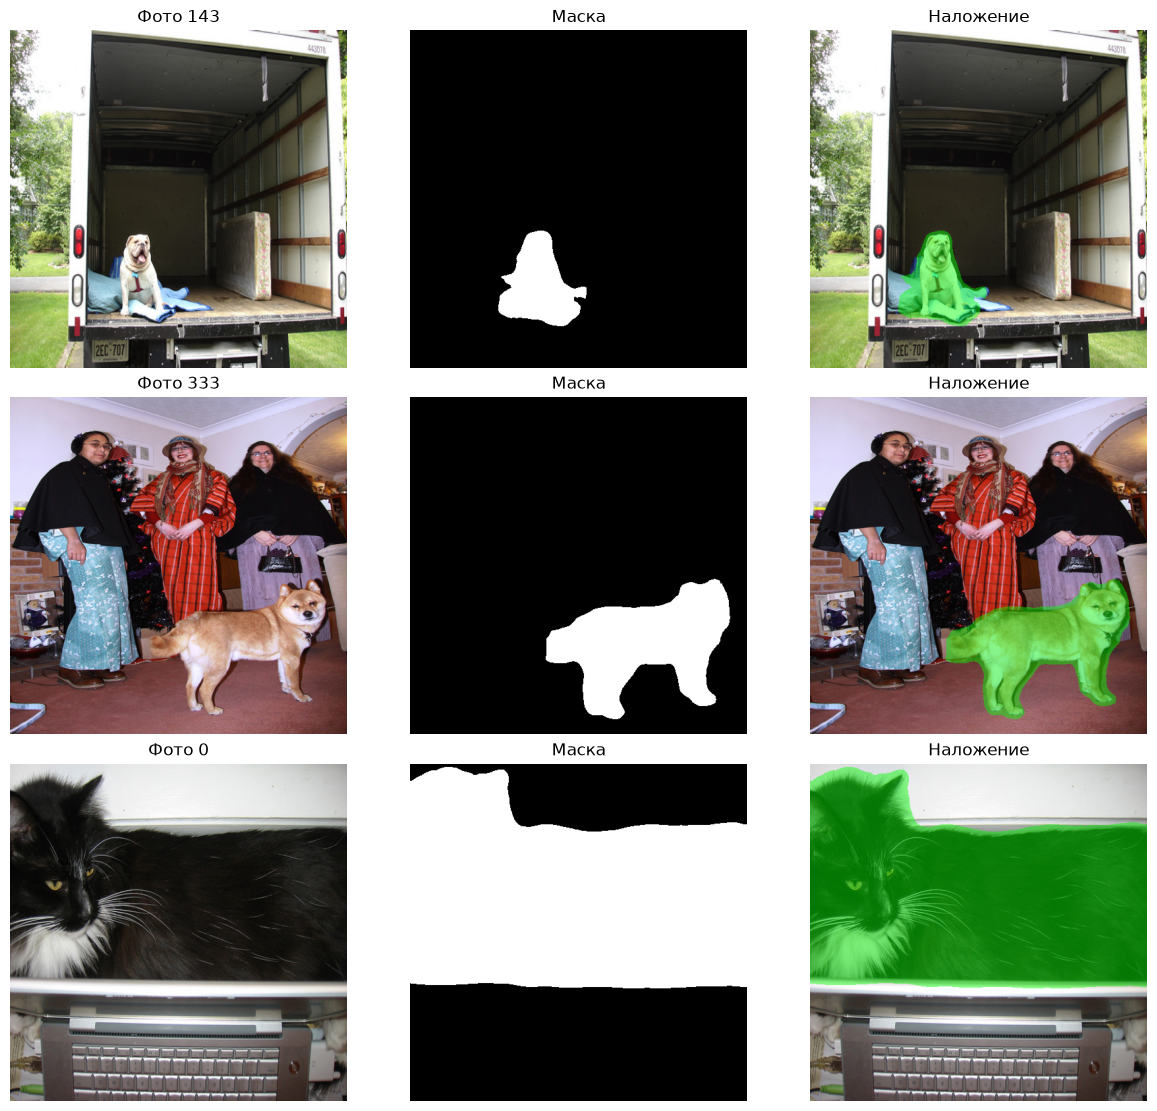

In [5]:
show_masks(result_014)


## 013. U-Net с ResNet18


In [6]:
result_013 = run(CHECKPOINT_013, competition_score=0.79133)


013_unet_resnet18_pretrained_strong_color
Valid IoU: 0.91682; питомец: 0.90827; фон: 0.92537
Совпали с исходным CSV: 349/349
Сохранено: predictions/reproduce/013_unet_resnet18_pretrained_strong_color/submission.csv


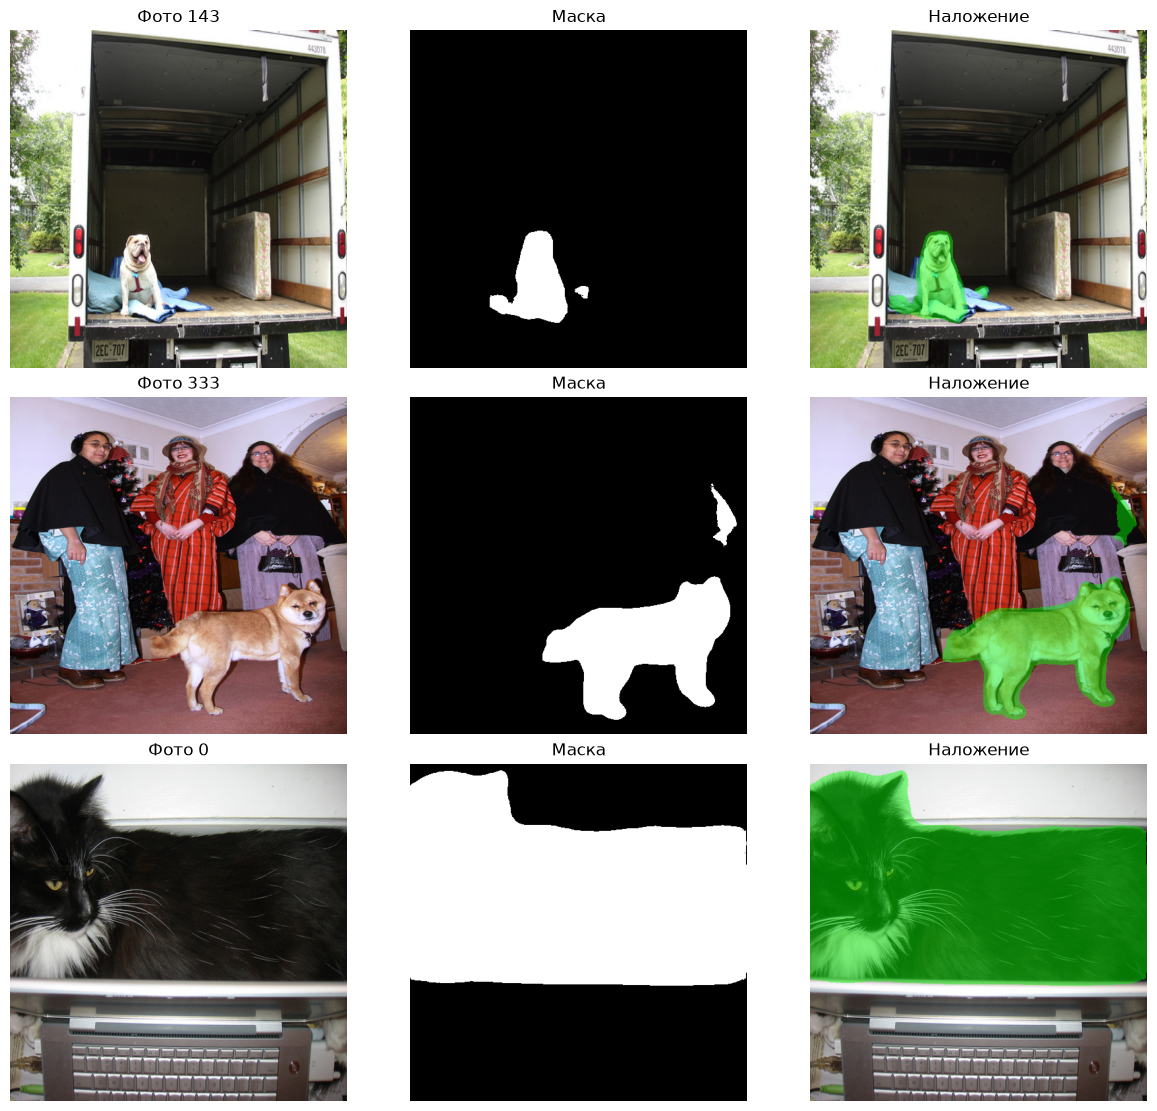

In [7]:
show_masks(result_013)


## Графики


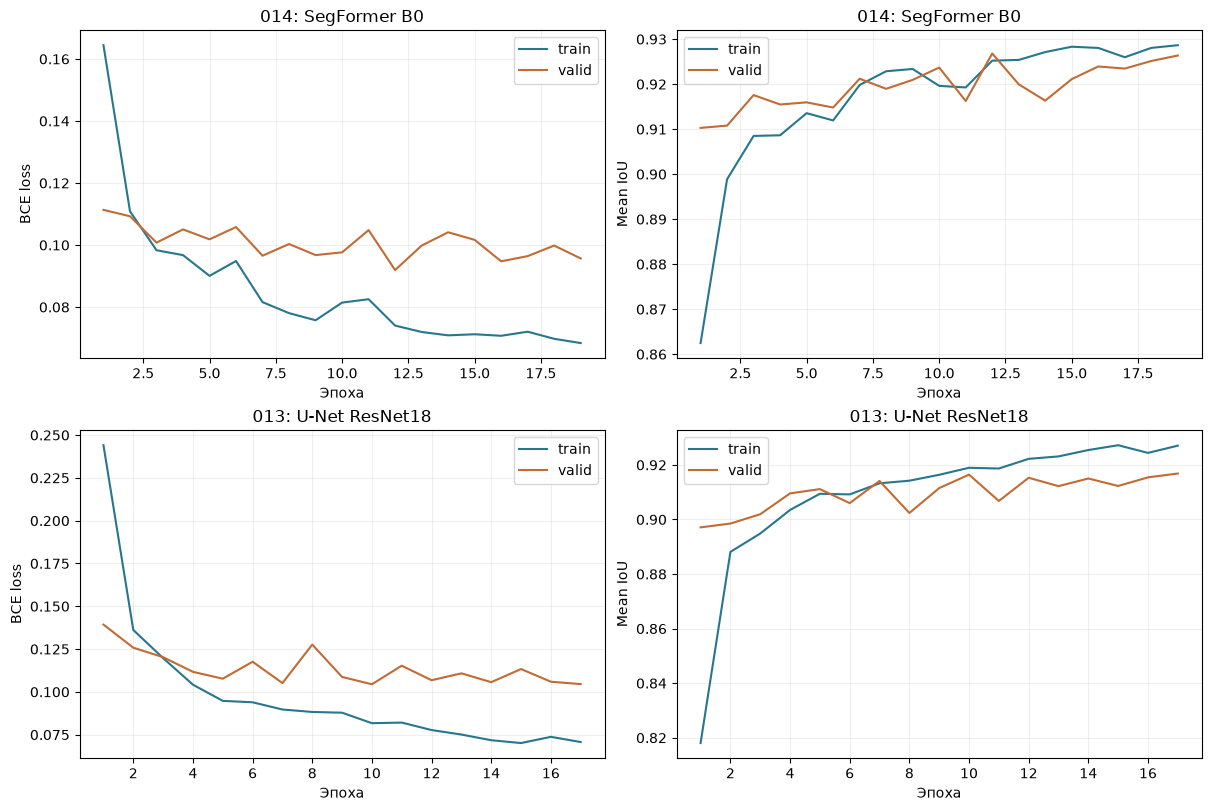

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for row, result in enumerate(results):
    logdirs = sorted({path.parent for path in Path(result["run_dir"]).rglob("*tfevents*")})
    if not logdirs:
        print("Нет TensorBoard-логов:", result["run_dir"])
        continue
    events = EventAccumulator(str(logdirs[0]), size_guidance={"scalars": 0})
    events.Reload()
    epochs = {point.step: int(point.value) + 1 for point in events.Scalars("epoch")}
    title = "014: SegFormer B0" if result["experiment"].startswith("014") else "013: U-Net ResNet18"
    for column, metric in enumerate(["loss_epoch", "iou"]):
        ax = axes[row, column]
        for stage, color in [("train", "#26778c"), ("valid", "#c16b35")]:
            points = events.Scalars(f"{stage}_{metric}")
            ax.plot([epochs[point.step] for point in points], [point.value for point in points], label=stage, color=color)
        ax.set(title=title, xlabel="Эпоха", ylabel="BCE loss" if column == 0 else "Mean IoU")
        ax.grid(alpha=0.2)
        ax.legend()
fig.savefig(OUTPUT_ROOT / "training_curves.png", dpi=160)
plt.show()


## Результаты


In [9]:
header = "| Эксперимент | Valid IoU | IoU питомца | Балл соревнования |\n| --- | ---: | ---: | ---: |\n"
table = "".join(f"| {row['experiment'][:3]} | {row['valid_mean_iou']:.5f} | {row['pet_iou']:.5f} | {row['competition_score']:.5f} |\n" for row in results)
display(Markdown(header + table))
print("Результаты:", OUTPUT_ROOT / "results.csv")
